# Workshop problems in Theoretical Neuroscience – Week 2

**Rune W. Berg¹, Rasmus Herlo²**

¹ Department of Neuroscience  
² Center for Translational Neuromedicine

Faculty of Health and Medical Sciences, University of Copenhagen, Blegdamsvej 3, 2200 Copenhagen, Denmark.

In [ ]:
%load_ext autoreload
%autoreload 2


%matplotlib inline

In [ ]:
from dataclasses import dataclass

from neuro.computation.nernst import nernst_potential

# 1 Single neuron models

## 1.1 Measuring Membrane resistance

Consider the figure below (Fig. 1). How would you determine the membrane resistance, $R_m$, of the cell? Assume $I=2\,\mathrm{nA}$ (black line).

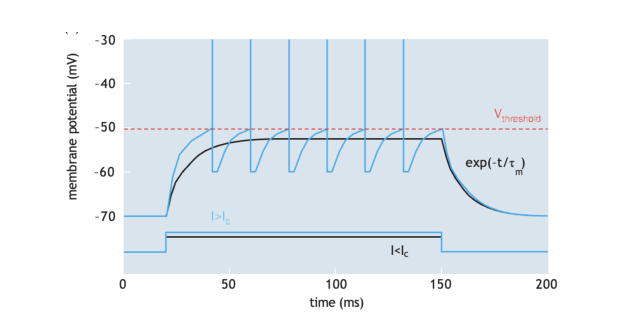

*Fig. 1. How would you estimate the membrane resistance from this measurement? Assume $I=2\,\mathrm{nA}$ (black line).*


In [ ]:
# NOTE: Does this figure show potential *and* current in the same plot?

Welp, a little more info would be helpful, but guessing we can get this from the membrane equation from last week?
That was (rearranging slightly)
$$C\frac{dV}{dt} + G(V - V_{rest}) = I_{app}$$

Considering the steady-state region at $V_{ss}$ where the membrane potential has stabilized near the threshold (so $dV / dt$ = 0), and using $G = 1/R$:
$$R = \frac{V_{ss} - V_{rest}}{I_{app}}$$

It looks like $V_{ss}$ as around $-52mV$, so
$$R \approx \frac{(-52 - (-70))\text{mV}}{2\text{nA}} = 9\text{M}\Omega$$
***

## 1.2 Dale’s law

What is Dale’s law?

Dale's Law states that a given neuron must either depolarize, or hyperpolarize, all of its postsynaptic neurons when firing.
***

## 1.3 Prediction of ionic channel strength from cytosolic components

Is there an intracellular component/metric that is not electrophysiological, i.e. current/conductance, that can predict the strength of a particular ionic channel conductance, e.g. $I_{Kd}$, $I_A$ and $I_{K(Ca)}$?

Not sure about this one. Strengh of conductance as in high conductance _right now_ (as in the channel is currently open), or as in the conductance can generally become very high during activation? If the former, ion concentrations maybe?
***

## 1.4 Synaptic input in the conductance based models

Write up the synaptic current in the conductance based model. Discuss the difference between current-based and conductance-based synaptic input and their functional consequences.

The conductance-based one is just the terms of the affected ion channels absorbed into a single conductance and reversal potential term:
$$I_{sym} = G_{syn}(V_m - E_{syn})$$

For instance, for a neurotransmitter affecting an arbitrary number of ion channels on the postsynaptic cell, we can collect the coefficients of the membrane potential $V_m$, and the constant terms arising from the reversal potentials:
$$
\begin{align*}
    I_{syn}
    &= \sum_i G_i (V_m - E_i) \\
    &= \left( \sum_i G_i \right)\cdot V_m - \sum_i G_i \cdot E_i \\
    &= G_{syn}(V_m - E_{syn}),
\end{align*}
$$
where
$$
\begin{align*}
    G_{syn} &= \sum_i G_i \quad \text{and} \\
    E_{syn} &= \frac{\sum_i G_i\cdot E_i}{\sum_i G_i}
\end{align*}
$$

So the synaptic conductance is just the sum over the conductances of affected channels, and the reversal potential is a weighted sum over the individual reversal potential of each, weighted by conductance

The difference between this, and modelling synaptic current as just some current $I_{syn}(t)$ is that the conductance-based takes into account interactions with the membrane potential.
***

## 1.5 Synaptic reversal potentials

Write down the synaptic reversal potentials and the primary electrolyte that carries the synaptic current for the following neurotransmitters in the table:

| Neurotransmitter | Primary Electrolyte | Reversal potential (mV) |
|---|---|---:|
| Glutamate |  |  |
| Acetylcholine (nicotinic) |  |  |
| Acetylcholine (muscarinic) |  |  |
| $\text{GABA}_A$ |  |  |
| $\text{GABA}_B$ |  |  |
| Glycine |  |  |


In [ ]:
# TODO define GHK equation, look up electrolytes, and compute E_syn 

Honestly I'm just looking this up in _Koch - Biophysics of Computation_.
Except Glycine. Looked that up to be permeable to chloride in Kandel.

| Neurotransmitter | Primary Electrolyte | Reversal potential (mV) |
|---|---|---:|
| Glutamate | $\text{Na}^+$, $\text{K}^+$ | 0 |
| Acetylcholine (nicotinic) |  | -5 |
| Acetylcholine (muscarinic) |  | -90 |
| $\text{GABA}_A$ |  | -70 |
| $\text{GABA}_B$ |  | -100 |
| Glycine | $\text{Cl}^-$ | -64 |

In [ ]:
@dataclass
class NeuroTransmitter:
    name: str
    primary_electrolyte: str


transmitters = [
    NeuroTransmitter(name, pe)
    for name, pe in (
        ("Glutamate", "K+"),
    )
]

for nt in transmitters:
    elt = electrolytes[nt.primary_electrolyte]
    e_rev = nernst_potential(elt.c_in, elt.c_out, elt.z)
    print(f"{nt.name}: primary electrolyte: {nt.primary_electrolyte}. E_rev={e_rev}")

## 1.6 Ornstein-Uhlenbeck noise

Explain how Ornstein-Uhlenbeck (OU) noise is achieved from a white noise current injection. Discuss what the difference between white noise and OU-noise is. Use the simulation in Github to simulate OU from white noise.

## 1.7 Autocorrelation function of OU and white noise

The autocorrelation function is a useful metric for investigating noise.

- Use the autocorrelation function to estimate the time constants of the three sample traces in the github Jupyter notebook ([https://github.com/RasHerlo/Theoretical_Neuroscience](https://github.com/RasHerlo/Theoretical_Neuroscience)).
- Write the time constants in the table below:

| OU process number | Estimated time constant |
|---:|---|
| 1 |  |
| 2 |  |
| 3 |  |


## 1.8 Return maps of OU and white noise

A return map is a plot where the data points on the x-axis is plotted against data points at a later time. Assume a function $f(t)$, each value of $f(t)$ is plotted on the x axis against itself at a later time $f(t+\tau)$, where $\tau$ is some appropriate delay.

- Plot a return map of the white noise process, choosing different values of $\tau$.
- Plot a similar return map for the OU process, choosing different values of $\tau$.
- Is there any qualitative difference?
- Discuss the difference with fellow students.


## 1.9 Power spectrum of white noise and OU process

From the textbook we know that a white noise power spectrum gives a delta function in the autocorrelation function. Discuss a similar relationship between OU process in time and frequency domain. What does the autocorrelation look like and what about the power spectrum?

## 1.10 Balanced E/I network and irregular spiking

Task: Use the Jupyter notebook that has a simulation of a balanced network of LIF neurons. What type of synapse is used here? Look at the spiking: does it look irregular? Try to change the intensity of synaptic input, either excitatory or inhibitory, i.e. "unbalancing" the synaptic input. How does it affect the irregularity? Discuss with a fellow student.

# 2 Basic Network Theory

## 2.1 Network architecture and adjacency matrices

### 2.1.1 Exercises for reflection

**Directed connectivity**

Connections in neural network graphs are directed. Explain in your own words what this means and why it matters for information flow. Give a concrete biological example of a directed projection in the nervous system.

**Adjacency matrix of a small network**

Consider a network of four neurons $\{A,B,C,D\}$ with the following directed, signed connections: $A\xrightarrow{+}B$, $A\xrightarrow{+}C$, $B\xrightarrow{-}D$, $C\xrightarrow{-}D$, $D\xrightarrow{-}A$.

1. Write the $4\times4$ signed adjacency matrix $W$, where $W_{ij}$ gives the weight of the connection from neuron $j$ to neuron $i$.
2. Which neuron(s) receive only inhibitory input? Which receive only excitatory input?
3. What would the adjacency matrix look like if you transposed it? What is the biological interpretation of the transpose?

**Adjacency matrix in a population rate model**

In the compendium, the network LIF model was described with a weight matrix $W$ governing synaptic interactions. Reflect on what the adjacency matrix looks like when neurons are not treated individually, but instead grouped into excitatory (E) and inhibitory (I) populations in a rate model. How does the dimension of the matrix change? What entries does it contain, and what is the biological meaning of each? How does this relate to the $g_{EE}$, $g_{EI}$, $g_{IE}$, $g_{II}$ coupling terms in the E/I balance model?


### 2.1.2 Pen-and-paper exercises

**Feedforward vs. recurrent architecture**

A feedforward network of three layers ($L_1\rightarrow L_2\rightarrow L_3$, each with two neurons) and a recurrent network with the same six neurons but with additional $L_2\rightarrow L_1$ feedback connections are given.

1. Write the $6\times6$ adjacency matrices for both networks. Use 1 for an excitatory connection and 0 for no connection.
2. How many non-zero entries does each matrix have? What does the difference tell you about the complexity of dynamics each network can support?
3. In which network can a perturbation of $L_1$ reach $L_1$ again? What is the minimum number of synaptic steps required?

**Connection probability and expected degree**

A local network has $N=200$ neurons. Each pair of neurons is connected independently with probability $p=0.05$.

1. What is the expected number of inputs $K$ to any single neuron?
2. Write the binomial expression for $P(C=k)$, the probability of a neuron receiving exactly $k$ inputs.
3. Under what conditions can this be well approximated by a Poisson distribution? Write the Poisson expression and verify that the mean and variance both equal $K$.
4. If $p$ is kept fixed and $N\rightarrow\infty$, does $K$ remain bounded? What if $K$ is fixed and $N\rightarrow\infty$?


## 2.2 Connection probability distributions

### 2.2.1 Exercises for reflection

**Choosing a distribution**

The compendium describes five distributions for modelling connection probability: Binomial, Poisson, Gaussian, Exponential, and Power-law. For each of the following biological scenarios, argue which distribution could be more appropriate and why:

1. A small, densely connected local cortical microcircuit with no spatial extent.
2. A large cortical area where connection probability decays with distance and most neurons have few long-range connections but a small number act as hubs.
3. A sensory layer where connectivity falls off smoothly with distance from a central point, with negligible long-range connections.


### 2.2.2 Jupyter exercises

**Plotting connection probability distributions**

Implement and plot all five connection probability distributions from the compendium in a single figure with subplots.

1. **Binomial:** Plot $P(C=k)$ for $N=100$, $p=0.05$. Overlay the Poisson approximation with $K=Np$ on the same axes. How well does the Poisson approximate the binomial?
2. **Poisson:** Plot $P(C=k)=\frac{K^k e^{-K}}{k!}$ for $K=5,10,20$. What happens to the shape as $K$ increases?
3. **Gaussian, Exponential, Power-law:** For a 1D array of neurons at positions $d\in[0,10]$, plot $p(d)$ for all three distance-dependent profiles on the same axes (choose parameters that give roughly comparable connection ranges). Label each curve clearly.
4. **Discuss:** Which profiles decay fastest with distance, and what does this imply for the spatial reach of influence of a single neuron?


## 2.3 Neuronal correlations and connectivity

### 2.3.1 Exercises for reflection

**Correlation as a proxy for connectivity**

The cross-correlation between two spike trains is described in the compendium as a proxy for connectivity, but not a guarantee of it.

1. Give an example of two neurons that would show strong cross-correlation without a direct synaptic connection between them. Draw a small circuit diagram to illustrate.
2. A narrow peak in the cross-correlogram at lag $\tau=0$ suggests synchronous co-activation. What does a peak at $\tau>0$ suggest? What does a trough at $\tau=0$ suggest?
3. In an E/I balanced network, would you expect the average pairwise noise correlation to be high or low? Justify your answer based on the properties of the balanced state described in the compendium.


### 2.3.2 Jupyter exercises

**Raster plot, pairwise correlations and the correlation matrix**

In this exercise you will generate synthetic spike trains, compute pairwise correlations, and reflect on how the resulting correlation matrix relates to the underlying connectivity.

1. **Generate spike trains.** Simulate $N=20$ neurons over $T=10\,\mathrm{s}$ with a time resolution of $\Delta t=1\,\mathrm{ms}$. Divide the neurons into two groups of 10. Within each group, neurons share a common Poisson input (firing rate $r_{\mathrm{common}}=20\,\mathrm{Hz}$) in addition to independent Poisson noise ($r_{\mathrm{ind}}=30\,\mathrm{Hz}$). Between groups, neurons receive only independent input. This simulates two internally correlated but mutually uncorrelated assemblies.

2. **Raster plot.** Display the spike trains of all 20 neurons as a raster plot (time on the x-axis, neuron index on the y-axis, each spike as a dot). Do the two groups appear visually distinguishable?

3. **Pairwise cross-correlograms.** Compute and plot the cross-correlogram $CC(\tau)$ for the following three pairs: (a) two neurons from the same group, (b) two neurons from different groups, (c) the same neuron with itself (autocorrelogram). What does the width and amplitude of the central peak tell you in each case?

4. **Spike count correlation matrix.** Bin the spike trains into $100\,\mathrm{ms}$ windows to obtain spike count vectors $n_i$ for each neuron $i$. Compute the $20\times20$ matrix of pairwise Pearson correlations:

   $$r_{ij}=\frac{\operatorname{Cov}(n_i,n_j)}{\sigma_i\sigma_j}\tag{1}$$

   Display this matrix as a heatmap with a diverging colormap centred at zero.

5. **Reflection.** Compare the structure of the correlation matrix to the connectivity structure you imposed (two groups with shared input).

   - Does the block structure of the connectivity appear in the correlation matrix?
   - Now imagine you were given only the correlation matrix and not told how the network was wired. What could you infer about the underlying connectivity, and what would remain ambiguous?
   - How would the correlation matrix change if the common input to each group were replaced by direct recurrent excitatory connections within each group?
